# TFS Assignment 1 — EEG Signal Analysis

**Student:** Pouya Bastani  
**Student ID:** 40530262  
**Course:** TFS

## Aim

This assignment examines EEG recordings from four task conditions—**Relax, Arithmetic, Mirror-image recognition, and Stroop**—using complementary time–frequency analyses. The first analysis filters the signals to the gamma range and uses the Hilbert transform to study amplitude, phase, instantaneous frequency, and a multichannel Pragmatic Information (PI) index. The second extracts short-window spectral features from the supplied recordings and evaluates four classifiers with participant-grouped cross-validation.

The goal is to understand what the signal representations reveal and how well they distinguish the recorded task labels, while keeping participant-level generalization and the limitations of these descriptive analyses in view.


# 1. Dataset and preprocessing

The MATLAB files in `Dataset/` contain cleaned recordings under the key `Clean_data`. The analysis treats each file as one condition–participant–trial recording and retains the channel-by-sample organization of the signal.


## 1.1 Load the recordings

The loader identifies the task condition from each filename and stores the recording name, condition, and EEG array together. This produces one row per recording, which makes later condition selection and feature extraction explicit.


In [60]:
!ls Dataset

Arithmetic_sub_10_trial1.mat	Relax_sub_10_trial1.mat
Arithmetic_sub_10_trial2.mat	Relax_sub_10_trial2.mat
Arithmetic_sub_10_trial3.mat	Relax_sub_10_trial3.mat
Arithmetic_sub_11_trial1.mat	Relax_sub_11_trial1.mat
Arithmetic_sub_11_trial2.mat	Relax_sub_11_trial2.mat
Arithmetic_sub_11_trial3.mat	Relax_sub_11_trial3.mat
Arithmetic_sub_12_trial1.mat	Relax_sub_12_trial1.mat
Arithmetic_sub_12_trial2.mat	Relax_sub_12_trial2.mat
Arithmetic_sub_12_trial3.mat	Relax_sub_12_trial3.mat
Arithmetic_sub_13_trial1.mat	Relax_sub_13_trial1.mat
Arithmetic_sub_13_trial2.mat	Relax_sub_13_trial2.mat
Arithmetic_sub_13_trial3.mat	Relax_sub_13_trial3.mat
Arithmetic_sub_14_trial1.mat	Relax_sub_14_trial1.mat
Arithmetic_sub_14_trial2.mat	Relax_sub_14_trial2.mat
Arithmetic_sub_14_trial3.mat	Relax_sub_14_trial3.mat
Arithmetic_sub_15_trial1.mat	Relax_sub_15_trial1.mat
Arithmetic_sub_15_trial2.mat	Relax_sub_15_trial2.mat
Arithmetic_sub_15_trial3.mat	Relax_sub_15_trial3.mat
Arithmetic_sub_16_trial1.mat	Relax_sub_16_tria

The directory listing confirms that the expected MATLAB recordings are available. The following loader maps their filenames to task labels and reads the `Clean_data` arrays into a table.


In [61]:
from scipy.io import loadmat
import os
import pandas as pd
import numpy as np

arithmetic = "Arithmetic"
mirror = "Mirror_image"
stroop = "Stroop"
relax = "Relax"

def eegData(path):
  data = os.listdir(path)
  test_path = os.path.join(path, data[0])
  eeg_pd = pd.DataFrame(columns=["NameOfData", "Condition" ,"Data"])

  for i in data:
    matPath = os.path.join(path, i)
    if i.startswith("Arithmetic"):
      eeg_pd.loc[len(eeg_pd)] = [i[:len(i)-4], arithmetic, loadmat(matPath)["Clean_data"]]
    elif i.startswith("Relax"):
      eeg_pd.loc[len(eeg_pd)] = [i[:len(i)-4], relax, loadmat(matPath)["Clean_data"]]
    elif i.startswith("Stroop"):
      eeg_pd.loc[len(eeg_pd)] = [i[:len(i)-4], stroop, loadmat(matPath)["Clean_data"]]
    else:
      eeg_pd.loc[len(eeg_pd)] = [i[:len(i)-4], mirror, loadmat(matPath)["Clean_data"]]

  return eeg_pd



In [62]:
path = "Dataset"

df = eegData(path)
df.head()

,NameOfData,Condition,Data
0,Mirror_image_sub_6_trial2,Mirror_image,"[[3.004357534257479, -6.722247181983583, -6.10..."
1,Mirror_image_sub_18_trial3,Mirror_image,"[[-2.2314779699918814, -7.598357006643672, 4.0..."
2,Mirror_image_sub_12_trial2,Mirror_image,"[[-9.857594732289265, 1.5375971503883128, 9.05..."
3,Stroop_sub_31_trial2,Stroop,"[[4.589442687045159, 6.5258043047170595, -2.04..."
4,Relax_sub_6_trial2,Relax,"[[-4.986686888163946, -2.457314425430681, -1.5..."


### Data-load check

The preview confirms that the loader produced a condition label and a multichannel data array for each listed recording. The dataset contains four conditions with 40 participants and three trials per condition, corresponding to 480 recordings in total. The saved analysis reports 32 channels and 3,200 samples per recording at 128 Hz (25 seconds).


## 1.2 Check condition counts

The next cell counts the Arithmetic and Mirror-image recordings. This is a simple balance check before comparing those two task labels; it does not test whether their EEG signals differ.


The count is a useful balance check for these two conditions. Equal recording counts prevent a simple difference in sample availability from dominating a descriptive comparison, although balance alone does not establish comparable signal quality.


In [63]:
math_counter = 0
mirror_counter = 0


for i in df["Condition"]:
  if i == arithmetic:
    math_counter += 1
  elif i == mirror:
    mirror_counter += 1

print(f"Arithmetic Data count: {math_counter} \nMirror Data count : {mirror_counter}")


Arithmetic Data count: 120 
Mirror Data count : 120


### Count result

The notebook reports **120 Arithmetic** and **120 Mirror-image** recordings. Each of these totals corresponds to 40 participants × 3 trials. The balance supports a straightforward descriptive comparison of these two subsets.


## 1.3 Gamma-band filtering

The sampling frequency is $f_s=128\,\mathrm{Hz}$, so the Nyquist frequency is

$$f_N=\frac{f_s}{2}=64\,\mathrm{Hz}.$$

A fourth-order Butterworth band-pass filter selects $30$–$45\,\mathrm{Hz}$ activity. The implementation uses second-order sections for numerical stability and `sosfiltfilt` for forward–backward, zero-phase filtering. The filtered signal is used for the Hilbert-transform branch; the Fourier-feature branch later starts from the supplied cleaned signal.


The filtering step isolates the 30–45 Hz gamma-band component. Because the data are sampled at 128 Hz, the chosen band lies below the 64 Hz Nyquist limit. The next plot compares an example raw channel with its filtered counterpart.


In [64]:
from scipy.signal import butter, sosfiltfilt

GAMMA = (30.0, 45.0)
def gamma_filter(x, fs=128, band=GAMMA, order = 4):
  sos = butter(order, band, btype='bandpass', fs=fs, output='sos')
  return sosfiltfilt(sos, x, axis=-1)


In [65]:
df["GammaData"] = None

for i ,raw_data in df["Data"].items():
  gamma_data = gamma_filter(raw_data)
  df.at[i, "GammaData"] = gamma_data

df.head()

,NameOfData,Condition,Data,GammaData
0,Mirror_image_sub_6_trial2,Mirror_image,"[[3.004357534257479, -6.722247181983583, -6.10...","[[0.006402852679920357, -1.217649505708799, -2..."
1,Mirror_image_sub_18_trial3,Mirror_image,"[[-2.2314779699918814, -7.598357006643672, 4.0...","[[0.022128576327967053, -8.141663642631558, 4...."
2,Mirror_image_sub_12_trial2,Mirror_image,"[[-9.857594732289265, 1.5375971503883128, 9.05...","[[-0.02055190981421562, -2.364804162512436, 1...."
3,Stroop_sub_31_trial2,Stroop,"[[4.589442687045159, 6.5258043047170595, -2.04...","[[0.007671429663787199, 2.855188729944632, -0...."
4,Relax_sub_6_trial2,Relax,"[[-4.986686888163946, -2.457314425430681, -1.5...","[[0.005393573696278631, -2.0438051496006686, 0..."


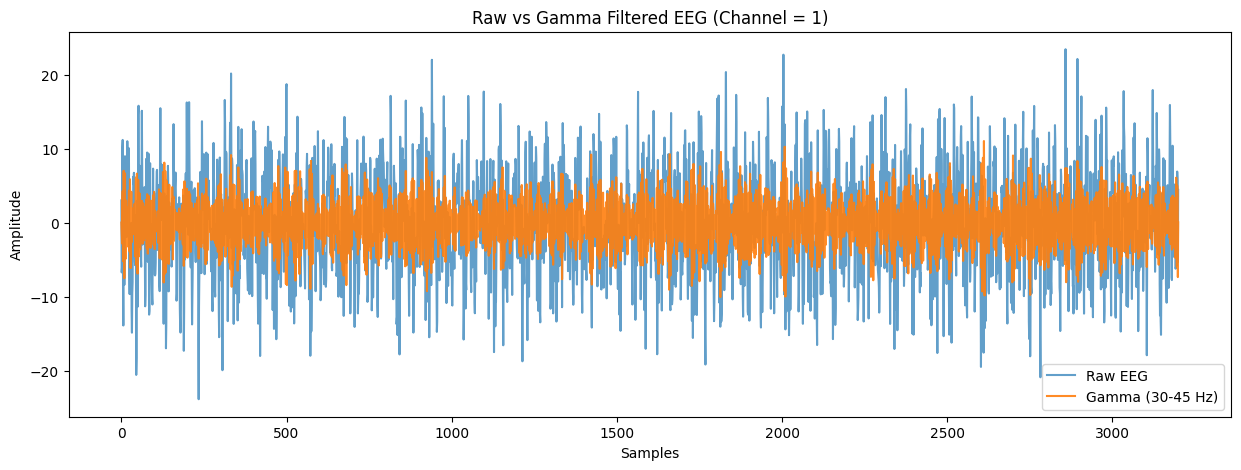

In [66]:
import matplotlib.pyplot as plt

raw = df["Data"].iloc[0]
gamma = df["GammaData"].iloc[0]

channel = 0

plt.figure(figsize=(15, 5))

plt.plot(raw[channel], label="Raw EEG", alpha=0.7)
plt.plot(gamma[channel], label="Gamma (30-45 Hz)", alpha=0.9)

plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.title("Raw vs Gamma Filtered EEG (Channel = 1)")
plt.legend()
plt.show()

### Interpretation — raw and gamma-filtered signal

The filtered trace retains the faster oscillatory component in the selected 30–45 Hz passband, whereas the raw trace contains the broader mixture of frequencies present in the cleaned recording. The two curves share the same amplitude scale, so filtering changes the waveform's temporal structure rather than serving as an amplitude normalization. This is one example channel and trial; it is not a group-level comparison.


# 2. Hilbert-transform analysis

The Hilbert transform provides a time-resolved description of the gamma-filtered signal. It is useful here for examining changes within a trial, rather than only summarizing average spectral content.


## 2.1 Analytic signal, envelope, phase, and instantaneous frequency

For a real-valued signal $x(t)$, the analytic signal is

$$z(t)=x(t)+j\,\mathcal{H}\{x(t)\}=A(t)e^{j\phi(t)},$$

where $\mathcal{H}\{x(t)\}$ is the Hilbert transform, $A(t)=|z(t)|$ is the amplitude envelope, and $\phi(t)=\arg z(t)$ is the phase. The phase is unwrapped before its finite difference is converted to instantaneous frequency:

$$f_{\mathrm{inst}}[n]=\frac{f_s}{2\pi}\left(\phi[n]-\phi[n-1]\right).$$

These quantities are calculated independently for each channel. Instantaneous frequency is especially sensitive to noisy phase and low-amplitude intervals, so isolated excursions should be interpreted cautiously.


For each recording and channel, the Hilbert transform converts the filtered waveform into a complex analytic signal. The resulting envelope and phase are then used to calculate instantaneous frequency by differencing the unwrapped phase. Since differencing reduces the number of time points by one, the instantaneous-frequency array has one fewer sample than the amplitude array.


In [67]:
from scipy.signal import hilbert

FS = 128
DURATION = 10
N_SAMPLES = FS * DURATION

df["AnalyticSignal"] = df["GammaData"].apply(lambda x: hilbert(x, axis=-1))

df["Amplitude"] = df["AnalyticSignal"].apply(lambda x: np.abs(x))
df["Phase"] = df["AnalyticSignal"].apply(lambda x: np.angle(x))
df["PhaseUnwrapped"] = df["Phase"].apply(lambda x: np.unwrap(x))
df["IF"] = df["PhaseUnwrapped"].apply(lambda x: np.diff(x) * FS / (2*np.pi))

df.head()


,NameOfData,Condition,Data,GammaData,AnalyticSignal,Amplitude,Phase,PhaseUnwrapped,IF
0,Mirror_image_sub_6_trial2,Mirror_image,"[[3.004357534257479, -6.722247181983583, -6.10...","[[0.006402852679920357, -1.217649505708799, -2...","[[(0.006402852679919988+0.8926224139027141j), ...","[[0.8926453776970724, 1.2262345400816053, 3.34...","[[1.5636233690379855, 3.023192313484553, -2.57...","[[1.5636233690379855, 3.023192313484553, 3.708...","[[29.73409437338767, 13.95161366371071, 31.965..."
1,Mirror_image_sub_18_trial3,Mirror_image,"[[-2.2314779699918814, -7.598357006643672, 4.0...","[[0.022128576327967053, -8.141663642631558, 4....","[[(0.02212857632796954+3.980765001898266j), (-...","[[3.98082650642155, 8.295814973142598, 9.07762...","[[1.5652375087312251, -2.94851415666401, -1.08...","[[1.5652375087312251, 3.334671150515576, 5.199...","[[36.04660615207341, 37.995122049405886, 40.94..."
2,Mirror_image_sub_12_trial2,Mirror_image,"[[-9.857594732289265, 1.5375971503883128, 9.05...","[[-0.02055190981421562, -2.364804162512436, 1....","[[(-0.020551909814215036+1.0521793195233848j),...","[[1.0523800175933145, 2.418379361481901, 2.854...","[[1.5903265497624346, -2.930710555929419, -1.0...","[[1.5903265497624346, 3.3524747512501674, 5.21...","[[35.89818838109003, 37.99618929210787, 39.310..."
3,Stroop_sub_31_trial2,Stroop,"[[4.589442687045159, 6.5258043047170595, -2.04...","[[0.007671429663787199, 2.855188729944632, -0....","[[(0.007671429663787421-1.224534280339488j), (...","[[1.2245583099875788, 2.8622297038405247, 3.31...","[[-1.564531635452127, -0.07015654478370341, 1....","[[-1.564531635452127, -0.07015654478370341, 1....","[[30.4431593616997, 37.77991478163034, 37.5828..."
4,Relax_sub_6_trial2,Relax,"[[-4.986686888163946, -2.457314425430681, -1.5...","[[0.005393573696278631, -2.0438051496006686, 0...","[[(0.005393573696279361+1.1093473025397544j), ...","[[1.1093604140627367, 2.1629786387357077, 2.44...","[[1.5659344308079133, -2.8080946888980285, -1....","[[1.5659344308079133, 3.4750906182815577, 4.83...","[[38.893010479476196, 27.774006815156035, 32.2..."


In [68]:
print(type(df['Amplitude'][0]))
print(df['Amplitude'][0].shape)

print(type(df['IF'][0]))
print(df['IF'][0].shape)

<class 'numpy.ndarray'>
(32, 3200)
<class 'numpy.ndarray'>
(32, 3199)


### Shape check

The output confirms an amplitude array of shape $(32, 3200)$ and an instantaneous-frequency array of shape $(32, 3199)$. The first dimension indexes channels; the second indexes samples. Instantaneous frequency is reported in hertz by the phase-difference formula.


This figure follows one example recording and channel through the Hilbert-derived quantities. The analytic-signal panel shows its real component; the amplitude panel shows the envelope, and wrapped and unwrapped phase are plotted together to show why phase unwrapping is needed before differentiation.


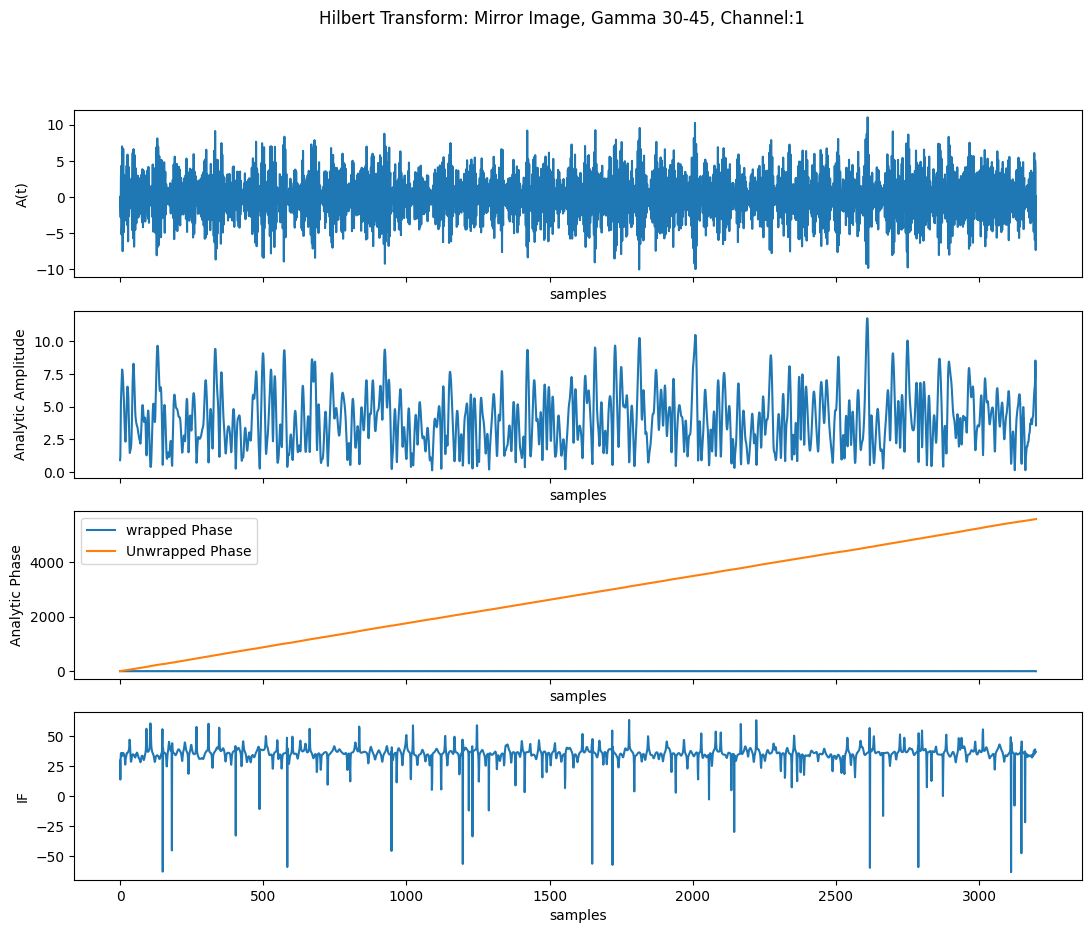

In [69]:
channel = 0


fig, ax = plt.subplots(4, 1, figsize=(13, 10), sharex=True)


ax[0].plot(df['AnalyticSignal'][0][channel].real)
ax[0].set_ylabel("Real part of z(t)")
ax[0].set_xlabel("samples")

ax[1].plot(df['Amplitude'][0][channel])
ax[1].set_ylabel("Analytic Amplitude")
ax[1].set_xlabel("samples")

ax[2].plot(df['Phase'][0][channel], label="wrapped Phase")
ax[2].plot(df["PhaseUnwrapped"][0][channel], label="Unwrapped Phase")
ax[2].legend()
ax[2].set_ylabel("Analytic Phase")
ax[2].set_xlabel("samples")

ax[3].plot(df['IF'][0][channel])
ax[3].set_ylabel("IF")
ax[3].set_xlabel("samples")

fig.suptitle("Hilbert Transform: Mirror Image, Gamma 30-45, Channel:1")
plt.show()

### Interpretation — time-varying Hilbert quantities

The envelope is nonstationary across this example, and the wrapped phase contains $2\pi$ discontinuities that are removed by unwrapping. The phase-derived frequency is consequently useful as a local description, but it can become unstable when the analytic amplitude is small or near the filter's edge transients. No physiological conclusion should be drawn from a single channel in one trial.


## 2.2 Pragmatic Information (PI) and peak rate

The PI calculation combines the mean squared analytic amplitude across channels with the phase difference between adjacent channels in the stored channel order. For $C$ channels,

$$P_A[n]=\frac{1}{C}\sum_{c=1}^{C}A_c[n]^2,$$

$$D_{\phi}[n]=\sqrt{\sum_{c=1}^{C-1}\operatorname{wrap}\!\left(\phi_{c+1}[n]-\phi_c[n]\right)^2},$$

$$PI[n]=\frac{P_A[n]}{D_{\phi}[n]+\epsilon}.$$

Here, `wrap` maps phase differences to the principal interval, and $\epsilon$ prevents division by zero. Because $D_{\phi}$ depends on channel ordering, the PI value is an implementation-specific spatial summary, not a channel-order-invariant physiological measure. The following calculation examines subject 1, trial 1, for Arithmetic, Mirror-image, and Relax, using the first 10 seconds of each recording. Peak rate is

$$NPS=\frac{N_{\mathrm{peaks}}}{T}\quad	ext{(peaks/s)}.$$

The code uses the median absolute deviation (MAD) as a prominence scale and enforces a minimum peak separation of 0.1 seconds.


The PI helper evaluates the phase differences between neighboring entries in the channel array and regularizes the denominator. Its exact definition is given above so that the influence of channel ordering and regularization remains explicit.


In [70]:
def pragmatic_index(amp, phase, eps_fraction=1e-8):
  pa = np.mean(amp**2, axis=0)
  adjacent = np.angle(np.exp(1j * (phase[1:] - phase[:-1])))
  dtheta = np.sqrt(np.sum(adjacent**2, axis=0))
  eps = max(np.finfo(float).eps, eps_fraction * np.median(dtheta))
  return pa / (dtheta + eps), eps


### PI and peak-rate calculation for subject 1, trial 1

The next cell computes the PI time series and reports its MAD, detected peak count, and peak rate for each of the three selected conditions.


The printed output gives a compact numerical summary of the three PI traces. The next cell plots those time series on a common time axis to compare their temporal variation.


In [71]:
from scipy.signal import find_peaks


DURATION = 10
N_SAMPLES = FS * DURATION

pi_results = {}

for condition in [arithmetic, mirror, relax]:

    trial_name = f"{condition}_sub_1_trial1"

    row = df.loc[df["NameOfData"] == trial_name].iloc[0]

    gamma = row["GammaData"][:, :N_SAMPLES]


    analytic = hilbert(gamma, axis=-1)

    amp = np.abs(analytic)
    phase = np.angle(analytic)

    pi, eps = pragmatic_index(amp, phase)

    pi_results[condition] = pi

    mad = np.median(np.abs(pi - np.median(pi)))

    peaks, _ = find_peaks(
        pi,
        prominence=max(mad, 1e-12),
        distance=int(0.1 * FS)
    )

    nps = len(peaks) / DURATION

    print(
        f"{condition}: "
        f"MAD={mad:.4f}, "
        f"Peaks={len(peaks)}, "
        f"NPS={nps:.2f} peaks/s"
    )

Arithmetic: MAD=1.8090, Peaks=51, NPS=5.10 peaks/s
Mirror_image: MAD=1.5793, Peaks=51, NPS=5.10 peaks/s
Relax: MAD=3.4899, Peaks=48, NPS=4.80 peaks/s


### PI and NPS results

| Condition | PI MAD | Detected peaks | NPS (peaks/s) |
|---|---:|---:|---:|
| Arithmetic | 1.8090 | 51 | 5.10 |
| Mirror-image | 1.5793 | 51 | 5.10 |
| Relax | 3.4899 | 48 | 4.80 |

Relax has the largest reported PI MAD in this 10-second sample, while Arithmetic and Mirror-image have the same detected peak rate. The peak rates are close; these values are descriptive and depend on the chosen prominence and minimum-distance settings.


The line plot compares the three PI traces over the selected 10-second interval. Shared axes make differences in amplitude and timing easier to inspect, but the traces represent one subject and one trial only.


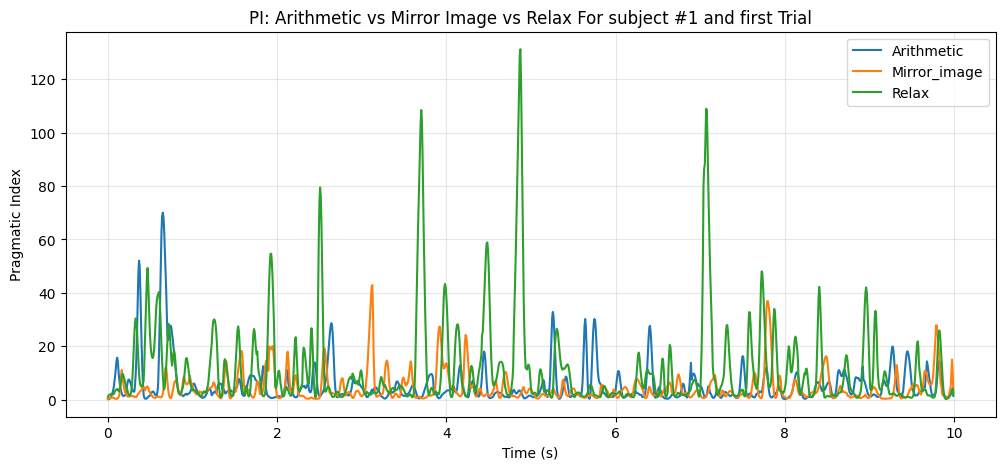

In [72]:
plt.figure(figsize=(12, 5))

for condition, pi in pi_results.items():
    t = np.arange(len(pi)) / FS
    plt.plot(t, pi, label=condition)

plt.xlabel("Time (s)")
plt.ylabel("Pragmatic Index")
plt.title("PI: Arithmetic vs Mirror Image vs Relax For subject #1 and first Trial")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Interpretation — PI trace

The plotted curves show transient variation rather than a constant PI value. The three traces have overlapping time-varying structure, and their amplitudes should not be interpreted as a population-level task effect: this PI comparison uses subject 1, trial 1, only. The peak-rate summary and PI magnitude capture different aspects of the trace, so a larger PI value does not automatically imply a higher event rate.


# 3. Fourier-transform features and classification

This branch describes the supplied cleaned EEG using short-window spectral features. Unlike the Hilbert branch, it uses the full available spectrum rather than filtering to the gamma band.


## 3.1 Windowed periodogram and spectral descriptors

Each recording is split into non-overlapping 0.5-second windows. At 128 Hz this gives 64 samples per window and a nominal frequency-bin spacing of $128/64=2\,\mathrm{Hz}$. A Hann window reduces spectral leakage. The periodogram is evaluated over the one-sided 0–64 Hz range, and four summaries are returned for each channel and window:

| Feature | Definition | Interpretation |
|---|---|---|
| Spectral entropy $H$ | $-\sum_k p_k\log_2 p_k$ | Distribution of spectral power across bins |
| Total power $TP$ | Sum of the PSD ordinates | Relative spectral magnitude under the chosen periodogram convention |
| Dominant frequency $DF$ | Frequency of the largest PSD ordinate | Most prominent frequency bin, quantized in 2 Hz steps |
| $PSK$ | $(\mu_f-DF)/\sigma_f$ | Assignment-defined standardized offset between spectral centroid and dominant frequency |

Here $p_k=P_k/\sum_jP_j$, $\mu_f=\sum_kp_kf_k$, and $\sigma_f$ is the power-weighted frequency spread. The PSD is normalized only for entropy and the frequency moments; the `TP` feature retains its magnitude information.


In [73]:
from scipy.signal import periodogram

Feature_name = ['H', 'TP', 'DF', 'PSK']
WINDOW_SECONDS = 0.5
WINDOW_SAMPLES = int(FS * WINDOW_SECONDS)

def ft_feature(trial):
  n_ch, n_samples = trial.shape
  n_win = n_samples // WINDOW_SAMPLES
  segments = trial[:, :n_win*WINDOW_SAMPLES].reshape(n_ch, n_win, WINDOW_SAMPLES).transpose(1,0,2)
  freqs, psd = periodogram(segments, fs=FS, window='hann', detrend='constant', scaling='density', axis=-1)
  df = freqs[1] - freqs[0]
  total_power = np.sum(psd, axis=-1) * df
  probs = psd / np.maximum(psd.sum(axis=-1, keepdims=True), np.finfo(float).eps)
  entropy = -np.sum(np.where(probs > 0, probs * np.log2(np.maximum(probs, np.finfo(float).tiny)), 0), axis=-1)
  dominant_idx = np.argmax(psd, axis=-1)
  dominant_freq = freqs[dominant_idx]
  mean_freq = np.sum(probs * freqs[None,None,:], axis=-1)
  sd_freq = np.sqrt(np.sum(probs * (freqs[None,None,:] - mean_freq[...,None])**2, axis=-1))
  psk = np.divide(mean_freq - dominant_freq, sd_freq, out=np.zeros_like(mean_freq), where=sd_freq > 1e-12)
  tensor = np.stack([entropy, total_power, dominant_freq, psk], axis=-1)
  return entropy, total_power, dominant_freq, psk, freqs, psd, tensor.reshape(n_win, -1)


The extraction loop applies the same feature function to every condition, participant, and trial. Each recording contributes 50 windows; each window has four features per channel. The participant identifier is retained as the grouping variable so that windows from one participant cannot appear in both training and test folds.


In [74]:
trial_number = np.arange(1, 4)
subject_number = np.arange(1, 41)
all_X, all_y, all_groups, all_trials = [], [], [], []
channel_tensors = []

df_feature = pd.DataFrame(columns=["condition", "subject", "trial", "entropy", "total_power", "dominant_freq", "psk", "freq", "psd", "data"])

for condition in [relax, arithmetic, mirror, stroop]:
  for sub in subject_number:
    for trial in trial_number:
      trial_name = f"{condition}_sub_{sub}_trial{trial}"
      row = df.loc[df["NameOfData"] == trial_name].iloc[0]
      data = row["Data"]
      entropy, TP, DF, psk, freq, psd, X_trial = ft_feature(data)
      df_feature.loc[len(df_feature)] = [condition, sub, trial, entropy, TP, DF, psk, freq, psd, data]

      all_X.append(X_trial)
      all_y.extend([condition] * len(X_trial))
      all_groups.extend([sub] * len(X_trial))
      all_trials.extend([f'{condition}_sub{sub}_trial{trial}'] * len(X_trial))
      channel_tensors.append((condition, sub, trial, X_trial))


X_ftm = np.vstack(all_X)
y = np.asarray(all_y)
groups = np.asarray(all_groups)
trial_ids = np.asarray(all_trials)

df_feature.head()


,condition,subject,trial,entropy,total_power,dominant_freq,psk,freq,psd,data
0,Relax,1,1,"[[4.065224902119622, 3.9655748958918347, 4.001...","[[71.96330604581395, 118.06304442059054, 122.4...","[[4.0, 4.0, 2.0, 10.0, 4.0, 28.0, 4.0, 4.0, 42...","[[1.1849885606534238, 0.8824327654449742, 1.08...","[0.0, 2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16...","[[[0.09191390855544447, 2.9961394322632993, 5....","[[3.133919636760634, -9.297742810537574, -16.5..."
1,Relax,1,2,"[[3.7053432161249353, 3.3914025468377273, 3.42...","[[65.28047563900978, 158.54523660748276, 171.4...","[[4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 36.0...","[[1.1947488020639683, 0.7909707734210215, 0.76...","[0.0, 2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16...","[[[0.13818534342093405, 1.4799221984439737, 7....","[[3.813591102669983, 5.040079686227686, 2.0666..."
2,Relax,1,3,"[[3.7609117585173726, 3.6905471635369427, 3.57...","[[26.471707290439053, 99.55557757177885, 121.7...","[[22.0, 4.0, 4.0, 4.0, 6.0, 24.0, 6.0, 4.0, 4....","[[-0.48675718127714174, 0.6923136093586046, 0....","[0.0, 2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16...","[[[0.04832828067871922, 1.6253212719320538, 1....","[[0.41940819192462353, -7.350509754872123, -10..."
3,Relax,2,1,"[[4.031838528463703, 3.8179572649584617, 3.804...","[[28.445397042510173, 27.589426389335376, 32.3...","[[34.0, 2.0, 2.0, 2.0, 28.0, 2.0, 34.0, 34.0, ...","[[-1.1310050010854589, 1.0089038967621102, 0.9...","[0.0, 2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16...","[[[0.04185186139701382, 0.5740207607332918, 1....","[[6.835691466469667, -6.769172455251976, -1.95..."
4,Relax,2,2,"[[3.444001969211787, 3.787470798083788, 3.7462...","[[41.682704102028104, 43.86530171748571, 52.95...","[[4.0, 18.0, 2.0, 2.0, 16.0, 16.0, 16.0, 18.0,...","[[1.011003836633202, 0.004026926392831983, 1.1...","[0.0, 2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16...","[[[0.1590894575281618, 2.1611950788061565, 4.3...","[[4.473805811142542, 0.9519704682913215, 0.391..."


This plot shows a normalized PSD for one channel and one example window. Normalization emphasizes spectral shape rather than absolute magnitude; the unnormalized PSD sum is retained separately as the total-power feature.


Text(0, 0.5, 'Power Spectrum Density')

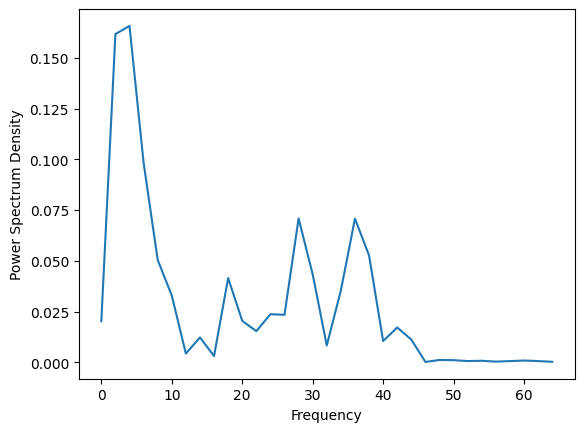

In [75]:
p = df_feature["psd"][0][0][1]
plt.plot(df_feature["freq"][0],  p/(p.sum()+1e-15))
plt.xlabel("Frequency")
plt.ylabel("Power Spectrum Density")

### Interpretation — example spectrum

The normalized spectrum emphasizes the relative distribution of power over frequency bins. The bin spacing is 2 Hz, so small shifts below this resolution are not distinguishable in an individual window. Because the plot is normalized, it should be interpreted alongside the unnormalized `TP` feature when comparing signal magnitude.


The feature arrays are gathered by recording and condition. The printed `(480, 4)` shape denotes 480 recording-level entries and four feature families; each entry contains the corresponding channel-by-window values. The classifier below uses the window-level vectors assembled by the extraction loop, not this compact recording-by-feature-family container.


In [76]:
tensor = np.stack([df_feature['entropy'], df_feature['dominant_freq'], df_feature['psk'], df_feature['total_power']], axis=1)
print(tensor.shape)
print(df_feature['condition'].unique())

(480, 4)
['Relax' 'Arithmetic' 'Mirror_image' 'Stroop']


The four panels compare the distributions of entropy, dominant frequency, $PSK$, and total power across task conditions. Overlapping histograms indicate that none of these features alone visibly separates all four labels. These are descriptive distributions; visual overlap is not a statistical test and does not account for dependence among windows from the same participant.


/tmp/ipykernel_572/613145618.py:35: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


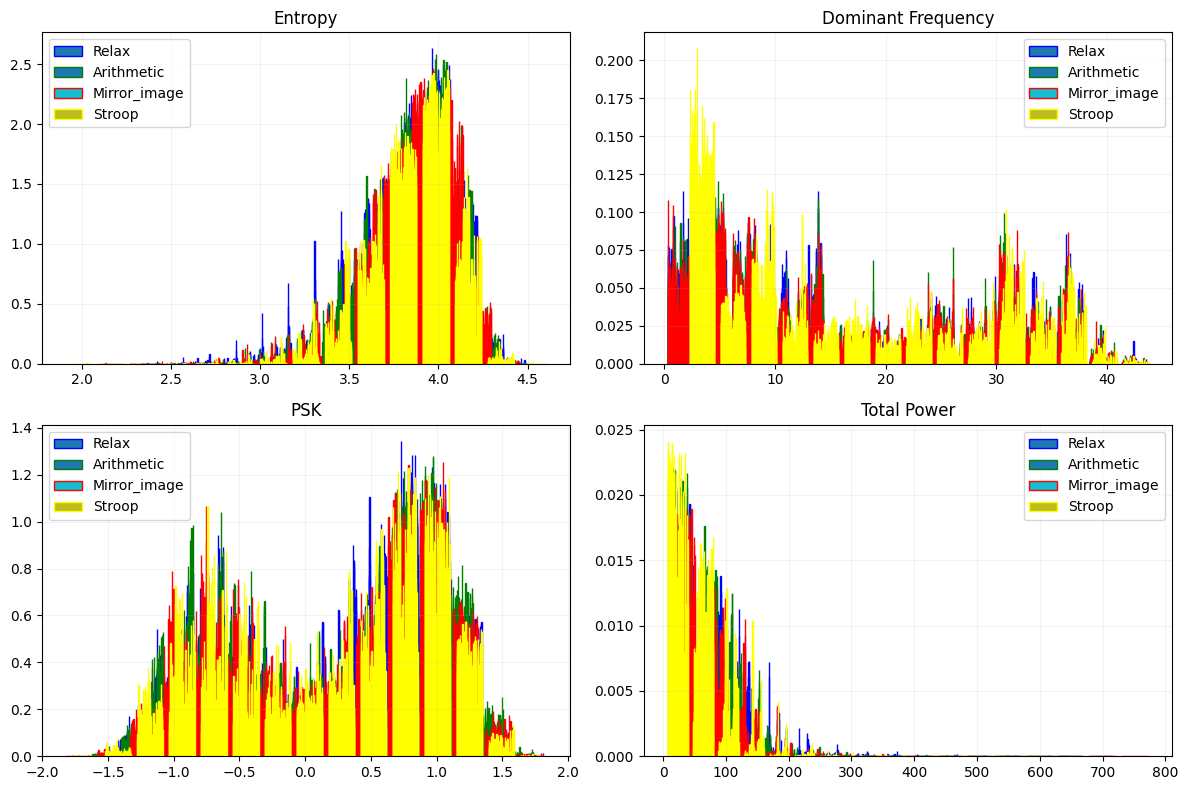

In [77]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0,0].hist(tensor[:120, 0], bins=15, edgecolor='blue', label="Relax", density=True)
axes[0,0].hist(tensor[121:240, 0], bins=15, edgecolor='green', label="Arithmetic", density=True)
axes[0,0].hist(tensor[241:360, 0], bins=15, edgecolor='red', label="Mirror_image", density=True)
axes[0,0].hist(tensor[361:480, 0], bins=15, edgecolor='yellow', label="Stroop", density=True)
axes[0,0].set_title("Entropy")
axes[0,0].grid(alpha=.15)
axes[0,0].legend()

axes[0,1].hist(tensor[:120, 1], bins=15, edgecolor='blue', label="Relax", density=True)
axes[0,1].hist(tensor[121:240, 1], bins=15, edgecolor='green', label="Arithmetic", density=True)
axes[0,1].hist(tensor[241:360, 1], bins=15, edgecolor='red', label="Mirror_image", density=True)
axes[0,1].hist(tensor[361:480, 1], bins=15, edgecolor='yellow', label="Stroop", density=True)
axes[0,1].set_title("Dominant Frequency")
axes[0,1].grid(alpha=.15)
axes[0,1].legend()

axes[1,0].hist(tensor[:120, 2], bins=15, edgecolor='blue', label="Relax", density=True)
axes[1,0].hist(tensor[121:240, 2], bins=15, edgecolor='green', label="Arithmetic", density=True)
axes[1,0].hist(tensor[241:360, 2], bins=15, edgecolor='red', label="Mirror_image", density=True)
axes[1,0].hist(tensor[361:480, 2], bins=15, edgecolor='yellow', label="Stroop", density=True)
axes[1,0].set_title("PSK")
axes[1,0].grid(alpha=.15)
axes[1,0].legend()

axes[1,1].hist(tensor[:120, 3], bins=15, edgecolor='blue', label="Relax", density=True)
axes[1,1].hist(tensor[121:240, 3], bins=15, edgecolor='green', label="Arithmetic", density=True)
axes[1,1].hist(tensor[241:360, 3], bins=15, edgecolor='red', label="Mirror_image", density=True)
axes[1,1].hist(tensor[361:480, 3], bins=15, edgecolor='yellow', label="Stroop", density=True)
axes[1,1].set_title("Total Power")
axes[1,1].grid(alpha=.15)
axes[1,1].legend()

plt.tight_layout()
plt.show()

The following label-order cell makes the confusion-matrix axes explicit and ensures all model reports use the same four-condition order.


In [ ]:
ACTIVITIES = [arithmetic, mirror, relax, stroop]


### Interpretation — feature distributions

The overlaid histograms show substantial overlap among conditions for all four displayed feature families. Entropy clusters within a relatively narrow range, while total power has a long right tail; dominant frequency is concentrated at discrete 2 Hz bins. These patterns help motivate multivariate classification, but they do not imply that the four tasks are statistically equivalent or that a classifier must fail.


## 3.2 Participant-held-out model evaluation

Four classifiers are evaluated using five-fold `GroupKFold`, with participant identity as the group. Thus, the model is tested on participants not used to train that fold, which is more appropriate for assessing transfer to unseen people than randomly splitting correlated windows. The data are balanced across the four conditions, giving a nominal uniform-guess accuracy of $1/4=0.25$.

Accuracy is the fraction of correct predictions. Macro-F1 gives each class equal weight:

$$F1_k=2\frac{P_kR_k}{P_k+R_k},\qquad \mathrm{Macro	ext{-}F1}=\frac{1}{4}\sum_{k=1}^{4}F1_k.$$

The confusion matrix uses true classes as rows and predicted classes as columns. Its diagonal counts correct classifications; off-diagonal entries show which tasks are confused.


Baseline grouped 5-fold accuracy: 0.3496
Baseline grouped 5-fold Macro-F1: 0.3421
              precision    recall  f1-score   support

  Arithmetic       0.34      0.33      0.34      6000
Mirror_image       0.30      0.20      0.24      6000
       Relax       0.35      0.37      0.36      6000
      Stroop       0.39      0.50      0.43      6000

    accuracy                           0.35     24000
   macro avg       0.34      0.35      0.34     24000
weighted avg       0.34      0.35      0.34     24000



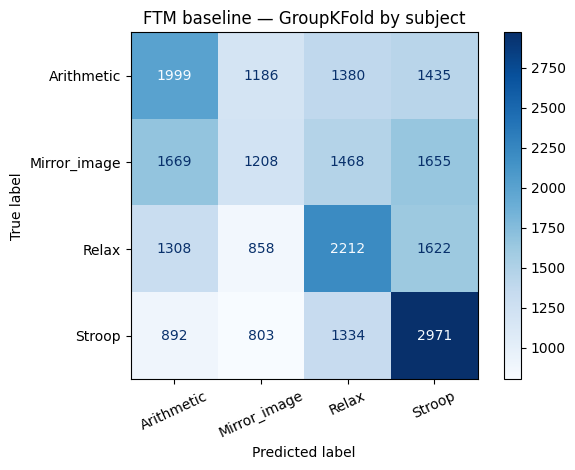

In [78]:

from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score, accuracy_score, classification_report,
    ConfusionMatrixDisplay
)


base_model = Pipeline([
    ('scale', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1500, class_weight='balanced', solver='lbfgs'))
])
outer_cv = GroupKFold(n_splits=5)
y_pred_base = cross_val_predict(base_model, X_ftm, y, groups=groups, cv=outer_cv, n_jobs=-1)
print('Baseline grouped 5-fold accuracy:', round(accuracy_score(y, y_pred_base), 4))
print('Baseline grouped 5-fold Macro-F1:', round(f1_score(y, y_pred_base, average='macro'), 4))
print(classification_report(y, y_pred_base, labels=ACTIVITIES, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y, y_pred_base, labels=ACTIVITIES, display_labels=ACTIVITIES, cmap='Blues', xticks_rotation=25)
plt.title('FTM baseline — GroupKFold by subject'); plt.tight_layout(); plt.show()

### Interpretation — Logistic Regression baseline

| True class | Correct predictions | Recall |
|---|---:|---:|
| Arithmetic | 1,999 / 6,000 | 0.33 |
| Mirror-image | 1,208 / 6,000 | 0.20 |
| Relax | 2,212 / 6,000 | 0.37 |
| Stroop | 2,971 / 6,000 | 0.50 |

The baseline achieves **0.3496 accuracy** and **0.3421 macro-F1**. The matrix shows the strongest recognition for Stroop and the weakest for Mirror-image. Mirror-image windows are distributed across the other three predictions, while Arithmetic is often labeled Relax or Stroop. This class-wise pattern explains why aggregate accuracy alone would hide the difficulty of recognizing Mirror-image trials.


The RBF support-vector machine provides a nonlinear decision boundary after feature standardization. Comparing its class-wise report and confusion matrix with the baseline helps show whether this alternative improves balanced four-class performance.


SVM grouped 5-fold accuracy: 0.3265
SVM grouped 5-fold Macro-F1: 0.3205
              precision    recall  f1-score   support

  Arithmetic       0.31      0.31      0.31      6000
Mirror_image       0.26      0.19      0.22      6000
       Relax       0.33      0.34      0.34      6000
      Stroop       0.37      0.46      0.41      6000

    accuracy                           0.33     24000
   macro avg       0.32      0.33      0.32     24000
weighted avg       0.32      0.33      0.32     24000



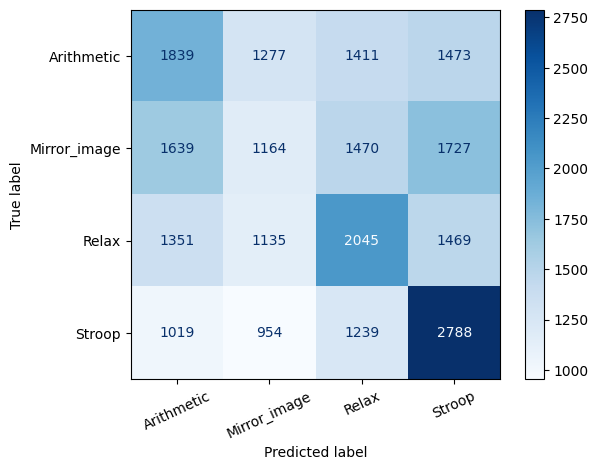

In [79]:
from sklearn.svm import SVC

svm_model = Pipeline([
    ('scale', StandardScaler()),
    ('clf', SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale',
        class_weight='balanced'
    ))
])

outer_cv = GroupKFold(n_splits=5)

y_pred_svm = cross_val_predict(
    svm_model, X_ftm, y,
    groups=groups,
    cv=outer_cv,
    n_jobs=-1
)

print('SVM grouped 5-fold accuracy:',
      round(accuracy_score(y, y_pred_svm), 4))

print('SVM grouped 5-fold Macro-F1:',
      round(f1_score(y, y_pred_svm, average='macro'), 4))

print(classification_report(
    y, y_pred_svm,
    labels=ACTIVITIES,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y, y_pred_svm,
    labels=ACTIVITIES,
    display_labels=ACTIVITIES,
    cmap='Blues',
    xticks_rotation=25
)

### Interpretation — SVM

The SVM reaches **0.3265 accuracy** and **0.3205 macro-F1**, below the Logistic Regression baseline on both metrics. Its matrix again shows the largest diagonal count for Stroop and the smallest for Mirror-image; Mirror-image is frequently assigned to Stroop. The nonlinear RBF boundary does not improve generalization to held-out participants in this run.


A single decision tree can represent nonlinear feature interactions but may be sensitive to the training sample. The same participant-grouped folds and evaluation metrics are retained so its results can be compared fairly with the other models.


In [80]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight='balanced',
    random_state=42
)

outer_cv = GroupKFold(n_splits=5)

y_pred_dt = cross_val_predict(
    dt_model, X_ftm, y,
    groups=groups,
    cv=outer_cv,
    n_jobs=-1
)

print('Decision Tree grouped 5-fold accuracy:',
      round(accuracy_score(y, y_pred_dt), 4))

print('Decision Tree grouped 5-fold Macro-F1:',
      round(f1_score(y, y_pred_dt, average='macro'), 4))

print(classification_report(
    y, y_pred_dt,
    labels=ACTIVITIES,
    zero_division=0
))

Decision Tree grouped 5-fold accuracy: 0.2727
Decision Tree grouped 5-fold Macro-F1: 0.2727
              precision    recall  f1-score   support

  Arithmetic       0.27      0.27      0.27      6000
Mirror_image       0.26      0.26      0.26      6000
       Relax       0.27      0.28      0.27      6000
      Stroop       0.30      0.29      0.29      6000

    accuracy                           0.27     24000
   macro avg       0.27      0.27      0.27     24000
weighted avg       0.27      0.27      0.27     24000



### Interpretation — Decision Tree

The Decision Tree records **0.2727 accuracy** and **0.2727 macro-F1**, only modestly above the 0.25 uniform-guess reference. Its class-wise F1 scores are similar (0.26–0.29), indicating relatively even but weak performance rather than strong recognition of one task. A single tree is the weakest of the four evaluated models by macro-F1.


The random forest averages predictions from an ensemble of decision trees. Its grouped validation setup is unchanged; the confusion matrix reveals whether its overall score reflects consistent recognition or uneven class performance.


Random Forest grouped 5-fold accuracy: 0.3185
Random Forest grouped 5-fold Macro-F1: 0.3137
              precision    recall  f1-score   support

  Arithmetic       0.31      0.29      0.30      6000
Mirror_image       0.27      0.21      0.23      6000
       Relax       0.32      0.35      0.34      6000
      Stroop       0.36      0.43      0.39      6000

    accuracy                           0.32     24000
   macro avg       0.31      0.32      0.31     24000
weighted avg       0.31      0.32      0.31     24000



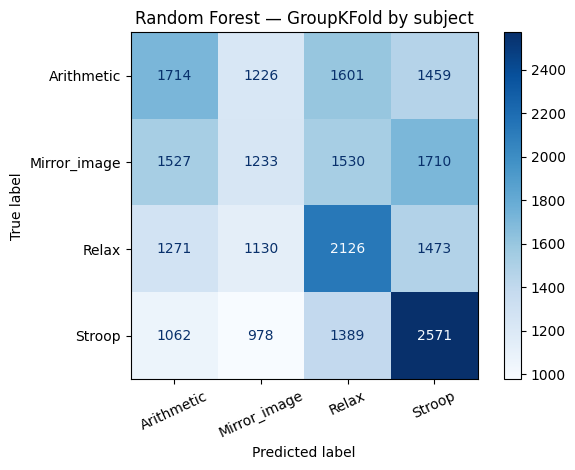

In [81]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

outer_cv = GroupKFold(n_splits=5)

y_pred_rf = cross_val_predict(
    rf_model,
    X_ftm,
    y,
    groups=groups,
    cv=outer_cv,
    n_jobs=1
)

print('Random Forest grouped 5-fold accuracy:',
      round(accuracy_score(y, y_pred_rf), 4))

print('Random Forest grouped 5-fold Macro-F1:',
      round(f1_score(y, y_pred_rf, average='macro'), 4))

print(classification_report(
    y, y_pred_rf,
    labels=ACTIVITIES,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y,
    y_pred_rf,
    labels=ACTIVITIES,
    display_labels=ACTIVITIES,
    cmap='Blues',
    xticks_rotation=25
)

plt.title('Random Forest — GroupKFold by subject')
plt.tight_layout()
plt.show()

### Interpretation — Random Forest

The Random Forest reaches **0.3185 accuracy** and **0.3137 macro-F1**. Stroop has the largest class recall (0.43), whereas Mirror-image again has the smallest (0.21). The ensemble improves on the single tree but remains below Logistic Regression and the nominal chance accuracy is not a substitute for a formal significance test.


This table aggregates the saved out-of-fold predictions for all four models. It ranks the models by their observed metrics but does not estimate uncertainty across participants.


In [84]:
predictions = {
    'Logistic Regression': y_pred_base,
    'SVM': y_pred_svm,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf
}

results = []

for model_name, y_pred in predictions.items():

    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y, y_pred),
        'Macro-F1': f1_score(y, y_pred, average='macro'),
        'Weighted-F1': f1_score(y, y_pred, average='weighted')
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).sort_values(
    by='Macro-F1', ascending=False
))


                 Model  Accuracy  Macro-F1  Weighted-F1
0  Logistic Regression    0.3496    0.3421       0.3421
1                  SVM    0.3265    0.3205       0.3205
3        Random Forest    0.3185    0.3137       0.3137
2        Decision Tree    0.2727    0.2727       0.2727


### Model comparison

| Model | Accuracy | Macro-F1 | Weighted-F1 |
|---|---:|---:|---:|
| Logistic Regression | **0.3496** | **0.3421** | **0.3421** |
| SVM (RBF) | 0.3265 | 0.3205 | 0.3205 |
| Random Forest | 0.3185 | 0.3137 | 0.3137 |
| Decision Tree | 0.2727 | 0.2727 | 0.2727 |

Logistic Regression ranks first on all three metrics in this saved run. Because the class supports are equal, macro- and weighted-F1 coincide to the displayed precision. The best accuracy is about 10 percentage points above the 25% uniform-guess baseline, but the absolute score remains modest. No confidence intervals, permutation test, or participant-level statistical comparison is included, so the ranking should be treated as a descriptive result rather than evidence of a decisive model advantage.


The grouped bar chart presents the same three metrics visually. The close metric values within each model and the comparatively low overall scores emphasize that performance is modest, even though it exceeds the nominal 25% uniform-guess baseline.


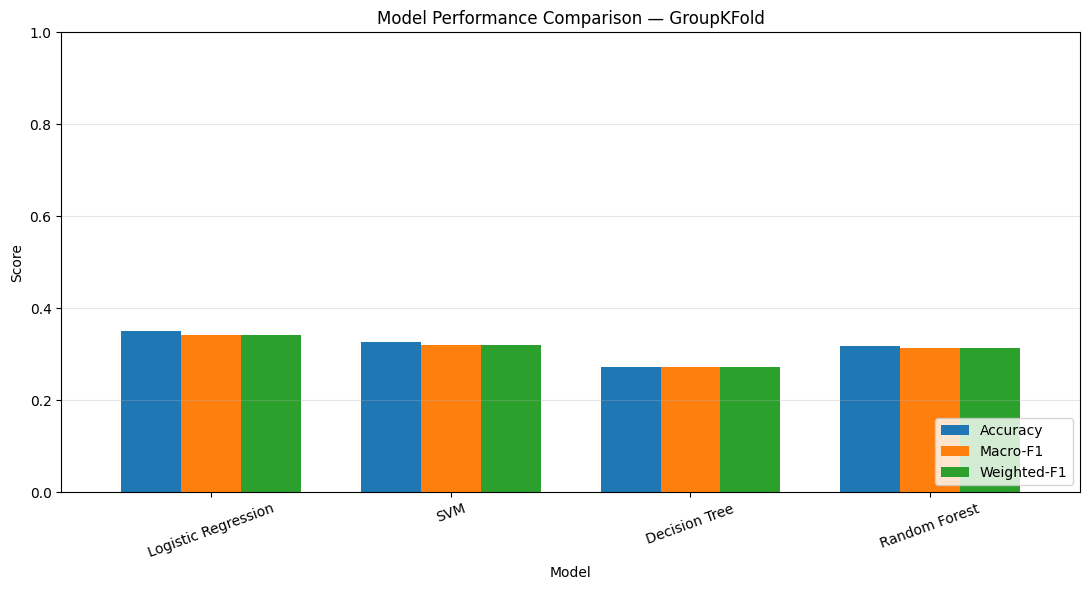

In [85]:

ax = results_df.set_index('Model')[
    ['Accuracy', 'Macro-F1', 'Weighted-F1']
].plot(
    kind='bar',
    figsize=(11, 6),
    width=0.75
)

plt.title('Model Performance Comparison — GroupKFold')
plt.ylabel('Score')
plt.xlabel('Model')
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretation — performance chart

The bar chart confirms the table: Logistic Regression is highest, the Decision Tree is lowest, and the SVM and Random Forest fall between them. The small separation among the top three models and all scores below 0.36 indicate that these features provide limited discrimination across unseen participants. The confusion matrices further show that this is not uniform across classes, especially for Mirror-image recognition.


# Conclusion

The notebook applies two complementary descriptions of the EEG: Hilbert-derived quantities track time-varying behavior in the selected gamma band, while windowed Fourier features summarize broader spectral content for classification. In the single-subject PI example, the three conditions produce similar peak rates (4.80–5.10 peaks/s), despite differences in PI variability. This is an illustrative within-trial observation, not evidence of a cohort-wide condition effect.

Under participant-grouped five-fold validation, Logistic Regression is the strongest of the four tested models (accuracy **0.3496**, macro-F1 **0.3421**), compared with the 0.25 uniform-guess reference. Performance remains modest, and the confusion matrices show that Stroop is more readily recognized than Mirror-image. The results therefore suggest limited task-related predictive information in the selected features, but not clean four-class separation or a physiological/clinical conclusion.

A stronger follow-up would quantify uncertainty across held-out participants, test against a participant-aware permutation baseline, and examine whether the PI result is robust to channel ordering and regularization. Those checks are necessary before interpreting small score differences or the illustrative PI contrast as reliable effects.
